# 07 Threshold Scenario Analysis

This notebook loads the **threshold-neutral** XGBoost holdout predictions and evaluates business scenarios without retraining the model.

 `MIN_BIKES_BUFFER` and `MIN_DOCKS_BUFFER` can be set a different levels. 
 The notebook will recompute:

- empty/full risk labels
- bike deficit and bike surplus
- station-hour summaries
- hourly aggregate plots
- top station-hour risk tables


In [4]:

import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path
from sklearn.metrics import classification_report

PROJECT_ROOT = Path('..').resolve()
PROCESSED_DIR = PROJECT_ROOT / 'data' / 'processed'
BUSINESS_VIEW_PATH = PROCESSED_DIR / 'xgb_business_view_threshold_neutral.parquet'

df_test = pd.read_parquet(BUSINESS_VIEW_PATH)
print("Loaded:", BUSINESS_VIEW_PATH)
print(df_test.shape)
print(df_test.columns.tolist())


Loaded: /home/tbeliere/Projects/DCU/2026-csc1144-dublin-bikes/data/processed/xgb_business_view_threshold_neutral.parquet
(6782627, 17)
['station_id', 'name', 'last_reported', 'hour', 'month', 'day', 'weekday', 'time', 'capacity', 'utilisation', 'current_bikes', 'true_utilisation_tplus_30', 'pred_utilisation_tplus_30', 'true_bikes_tplus_30', 'pred_bikes_tplus_30', 'true_free_docks_tplus_30', 'pred_free_docks_tplus_30']


## 1. Global Threshold-Based Risk and Imbalance Analysis

Evaluates the bike-sharing system at a network level using predefined operational thresholds

In [49]:
def run_threshold_analysis(df_input, min_bikes_buffer=3, min_docks_buffer=3):
    import matplotlib.pyplot as plt
    from sklearn.metrics import classification_report

    df = df_input.copy()

    name_candidates = ["name", "station_name", "station_name_clean"]
    name_col = next((c for c in name_candidates if c in df.columns), None)

    # clip predictions to physical bounds
    df["pred_bikes_tplus_30_clipped"] = df["pred_bikes_tplus_30"].clip(lower=0, upper=df["capacity"])
    df["pred_free_docks_tplus_30_clipped"] = df["capacity"] - df["pred_bikes_tplus_30_clipped"]

    # true labels
    df["empty_risk_true"] = df["true_bikes_tplus_30"] <= min_bikes_buffer
    df["full_risk_true"] = df["true_free_docks_tplus_30"] <= min_docks_buffer

    # predicted labels
    df["empty_risk_pred"] = df["pred_bikes_tplus_30_clipped"] <= min_bikes_buffer
    df["full_risk_pred"] = df["pred_free_docks_tplus_30_clipped"] <= min_docks_buffer

    # deficit / surplus
    df["bike_deficit"] = (min_bikes_buffer - df["pred_bikes_tplus_30_clipped"]).clip(lower=0)
    df["bike_surplus"] = (
        df["pred_bikes_tplus_30_clipped"] - (df["capacity"] - min_docks_buffer)
    ).clip(lower=0)

    # risk label
    df["risk"] = "normal"
    df.loc[df["empty_risk_pred"], "risk"] = "empty"
    df.loc[df["full_risk_pred"], "risk"] = "full"

    print(f"=== BIKE-BASED EMPTY RISK ({min_bikes_buffer}/{min_docks_buffer}) ===")
    print(classification_report(df["empty_risk_true"], df["empty_risk_pred"], zero_division=0))

    print(f"=== BIKE-BASED FULL RISK ({min_bikes_buffer}/{min_docks_buffer}) ===")
    print(classification_report(df["full_risk_true"], df["full_risk_pred"], zero_division=0))

    group_cols = ["station_id", "hour"]
    if name_col is not None:
        group_cols.insert(1, name_col)

    station_hour_summary = (
        df.groupby(group_cols, as_index=False)
        .agg(
            predicted_bikes_mean=("pred_bikes_tplus_30_clipped", "mean"),
            predicted_bikes_std=("pred_bikes_tplus_30_clipped", "std"),
            deficit_mean=("bike_deficit", "mean"),
            surplus_mean=("bike_surplus", "mean"),
            deficit_sum=("bike_deficit", "sum"),
            surplus_sum=("bike_surplus", "sum"),
            n_empty_risk=("empty_risk_pred", "sum"),
            n_full_risk=("full_risk_pred", "sum"),
            p_empty_risk=("empty_risk_pred", "mean"),
            p_full_risk=("full_risk_pred", "mean"),
            n_obs=("station_id", "size"),
            capacity=("capacity", "first"),
        )
    )

    station_hour_summary["predicted_bikes_mean"] = station_hour_summary["predicted_bikes_mean"].round(1)
    station_hour_summary["predicted_bikes_std"] = station_hour_summary["predicted_bikes_std"].fillna(0).round(1)
    station_hour_summary["deficit_mean"] = station_hour_summary["deficit_mean"].round(2)
    station_hour_summary["surplus_mean"] = station_hour_summary["surplus_mean"].round(2)
    station_hour_summary["p_empty_risk"] = station_hour_summary["p_empty_risk"].round(3)
    station_hour_summary["p_full_risk"] = station_hour_summary["p_full_risk"].round(3)

    station_hour_summary["risk"] = "normal"
    station_hour_summary.loc[station_hour_summary["n_empty_risk"] > 0, "risk"] = "empty"
    station_hour_summary.loc[station_hour_summary["n_full_risk"] > 0, "risk"] = "full"

    summary_cols = [
        "station_id", "hour", "predicted_bikes_mean", "predicted_bikes_std",
        "deficit_mean", "surplus_mean", "n_empty_risk", "n_full_risk", "risk"
    ]
    if name_col is not None:
        summary_cols.insert(1, name_col)

    display(station_hour_summary[summary_cols].head(20))

    top_station_risk_summary = station_hour_summary.sort_values(
        ["deficit_mean", "surplus_mean", "predicted_bikes_mean"],
        ascending=[False, False, True]
    )[summary_cols].head(10)

    print("Top station-hour risk summary")
    display(top_station_risk_summary)

    agg_hour = (
        station_hour_summary
        .groupby("hour", as_index=False)
        .agg(
            total_deficit=("deficit_mean", "sum"),
            total_surplus=("surplus_mean", "sum"),
            mean_deficit=("deficit_mean", "mean"),
            mean_surplus=("surplus_mean", "mean"),
            total_predicted_bikes=("predicted_bikes_mean", "sum"),
            mean_predicted_bikes=("predicted_bikes_mean", "mean"),
        )
    )

    agg_hour_risk = (
        station_hour_summary
        .groupby("hour", as_index=False)
        .agg(
            total_empty_risk=("n_empty_risk", "sum"),
            total_full_risk=("n_full_risk", "sum"),
            mean_empty_risk=("p_empty_risk", "mean"),
            mean_full_risk=("p_full_risk", "mean"),
        )
    )

    # Global deficit / surplus
    fig, axes = plt.subplots(1, 2, figsize=(14, 5), sharex=True)

    axes[0].plot(agg_hour["hour"], agg_hour["total_deficit"], label="Total Deficit")
    axes[0].plot(agg_hour["hour"], agg_hour["total_surplus"], label="Total Surplus")
    axes[0].set_title(f"Deficit / Surplus by Hour - Total ({min_bikes_buffer}/{min_docks_buffer})")
    axes[0].set_xlabel("Hour of Day")
    axes[0].set_ylabel("Number of Bikes")
    axes[0].legend()
    axes[0].grid(True)

    axes[1].plot(agg_hour["hour"], agg_hour["mean_deficit"], label="Mean Deficit")
    axes[1].plot(agg_hour["hour"], agg_hour["mean_surplus"], label="Mean Surplus")
    axes[1].set_title(f"Deficit / Surplus by Hour - Mean ({min_bikes_buffer}/{min_docks_buffer})")
    axes[1].set_xlabel("Hour of Day")
    axes[1].set_ylabel("Bikes per Station")
    axes[1].legend()
    axes[1].grid(True)

    plt.tight_layout()
    plt.show()

    # Global risk
    fig, axes = plt.subplots(1, 2, figsize=(14, 5), sharex=True)

    axes[0].plot(agg_hour_risk["hour"], agg_hour_risk["total_empty_risk"], label="Total Empty Risk")
    axes[0].plot(agg_hour_risk["hour"], agg_hour_risk["total_full_risk"], label="Total Full Risk")
    axes[0].set_title(f"Risk by Hour - Total ({min_bikes_buffer}/{min_docks_buffer})")
    axes[0].set_xlabel("Hour of Day")
    axes[0].set_ylabel("Count of Risk Events")
    axes[0].legend()
    axes[0].grid(True)

    axes[1].plot(agg_hour_risk["hour"], agg_hour_risk["mean_empty_risk"], label="Mean Empty Risk")
    axes[1].plot(agg_hour_risk["hour"], agg_hour_risk["mean_full_risk"], label="Mean Full Risk")
    axes[1].set_title(f"Risk by Hour - Mean ({min_bikes_buffer}/{min_docks_buffer})")
    axes[1].set_xlabel("Hour of Day")
    axes[1].set_ylabel("Average Risk Rate")
    axes[1].legend()
    axes[1].grid(True)

    plt.tight_layout()
    plt.show()

    # Global predicted bikes
    fig, axes = plt.subplots(1, 2, figsize=(14, 5), sharex=True)

    axes[0].plot(agg_hour["hour"], agg_hour["total_predicted_bikes"], label="Total Predicted Bikes")
    axes[0].set_title(f"Predicted Bikes by Hour - Total ({min_bikes_buffer}/{min_docks_buffer})")
    axes[0].set_xlabel("Hour of Day")
    axes[0].set_ylabel("Total Bikes")
    axes[0].legend()
    axes[0].grid(True)

    axes[1].plot(agg_hour["hour"], agg_hour["mean_predicted_bikes"], label="Mean Predicted Bikes")
    axes[1].set_title(f"Predicted Bikes by Hour - Mean ({min_bikes_buffer}/{min_docks_buffer})")
    axes[1].set_xlabel("Hour of Day")
    axes[1].set_ylabel("Average Bikes per Station")
    axes[1].legend()
    axes[1].grid(True)

    plt.tight_layout()
    plt.show()

    return df, station_hour_summary, agg_hour, agg_hour_risk, top_station_risk_summary

=== BIKE-BASED EMPTY RISK (3/3) ===
              precision    recall  f1-score   support

       False       0.96      0.97      0.97   4984104
        True       0.92      0.90      0.91   1798523

    accuracy                           0.95   6782627
   macro avg       0.94      0.93      0.94   6782627
weighted avg       0.95      0.95      0.95   6782627

=== BIKE-BASED FULL RISK (3/3) ===
              precision    recall  f1-score   support

       False       0.98      0.99      0.98   6139805
        True       0.88      0.81      0.84    642822

    accuracy                           0.97   6782627
   macro avg       0.93      0.90      0.91   6782627
weighted avg       0.97      0.97      0.97   6782627



,station_id,name,hour,predicted_bikes_mean,predicted_bikes_std,deficit_mean,surplus_mean,n_empty_risk,n_full_risk,risk
0,1,CLARENDON ROW,0,8.9,8.8,1.02,0.01,888,20,full
1,1,CLARENDON ROW,1,8.6,8.7,1.06,0.00,861,19,full
2,1,CLARENDON ROW,2,8.6,8.7,1.07,0.01,901,20,full
3,1,CLARENDON ROW,3,8.7,8.8,1.05,0.01,897,24,full
4,1,CLARENDON ROW,4,9.0,8.4,0.76,0.00,925,22,full
5,1,CLARENDON ROW,5,10.9,8.1,0.23,0.02,637,58,full
6,1,CLARENDON ROW,6,13.6,7.6,0.02,0.07,145,168,full
7,1,CLARENDON ROW,7,16.3,7.1,0.01,0.11,25,238,full
8,1,CLARENDON ROW,8,18.3,6.8,0.00,0.08,26,313,full
9,1,CLARENDON ROW,9,20.3,6.4,0.00,0.10,15,352,full


Top station-hour risk summary


,station_id,name,hour,predicted_bikes_mean,predicted_bikes_std,deficit_mean,surplus_mean,n_empty_risk,n_full_risk,risk
1179,51,YORK STREET WEST,3,1.0,4.4,2.78,0.0,1892,0,empty
1176,51,YORK STREET WEST,0,1.0,4.6,2.77,0.0,1942,0,empty
1177,51,YORK STREET WEST,1,1.0,4.6,2.77,0.0,1886,0,empty
1178,51,YORK STREET WEST,2,1.0,4.5,2.77,0.0,1897,0,empty
1180,51,YORK STREET WEST,4,1.1,4.5,2.76,0.0,1995,0,empty
1199,51,YORK STREET WEST,23,1.1,4.8,2.76,0.0,1998,0,empty
1198,51,YORK STREET WEST,22,1.1,4.7,2.75,0.0,1878,0,empty
1197,51,YORK STREET WEST,21,1.2,4.8,2.73,0.0,1887,6,full
1196,51,YORK STREET WEST,20,1.2,4.9,2.70,0.0,1881,7,full
1194,51,YORK STREET WEST,18,1.4,4.8,2.57,0.0,1870,0,empty


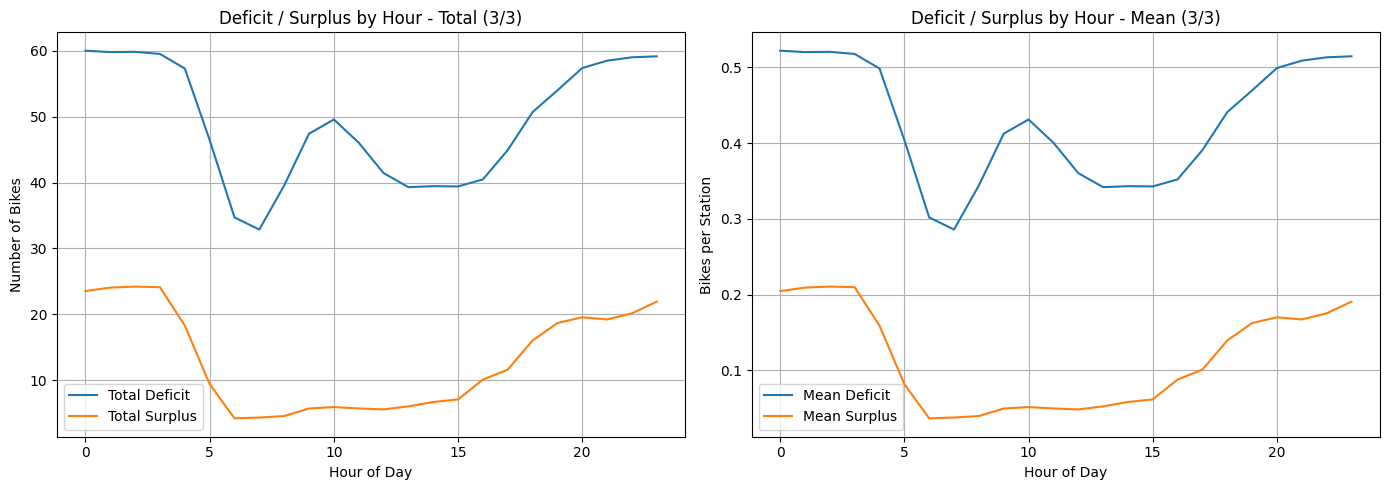

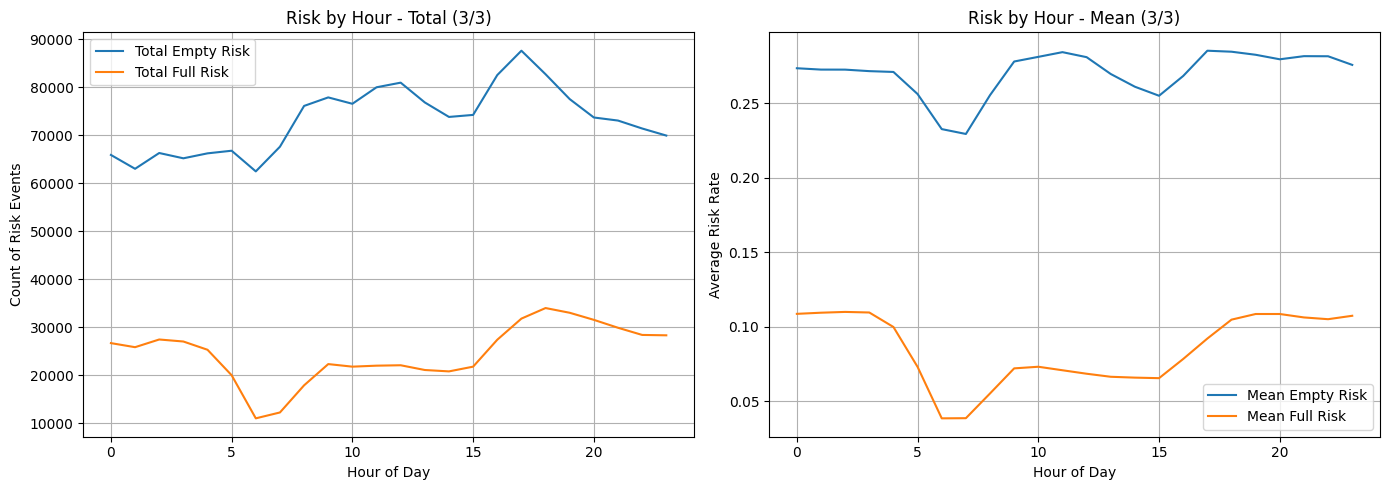

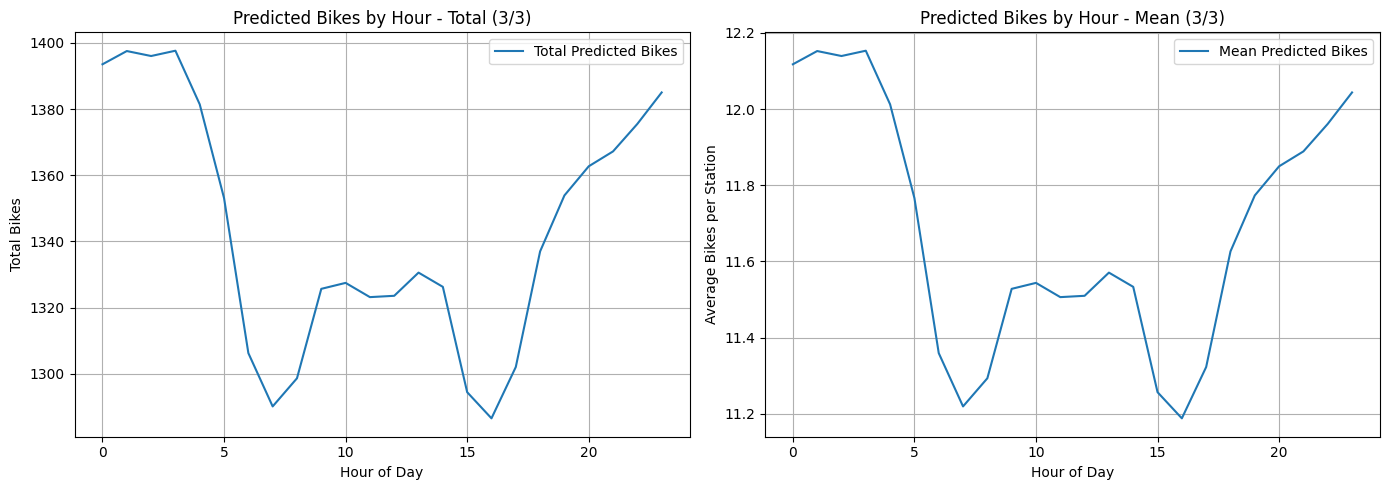

In [ ]:
# Run analysis with specified thresholds

MIN_BIKES_BUFFER = 3
MIN_DOCKS_BUFFER = 3

df_threshold, station_hour_summary, agg_hour, agg_hour_risk, top_station_risk_summary = run_threshold_analysis(
    df_test,
    min_bikes_buffer=MIN_BIKES_BUFFER,
    min_docks_buffer=MIN_DOCKS_BUFFER,
)

## 2. Top risk stations - ranking

In [21]:
# aggregate by station to find top risk stations
station_risk_summary = (
    station_hour_summary
    .groupby("station_id", as_index=False)
    .agg(
        avg_deficit=("deficit_mean", "mean"),
        avg_surplus=("surplus_mean", "mean"),
        avg_empty_risk=("p_empty_risk", "mean"),
        avg_full_risk=("p_full_risk", "mean"),
    )
)

# rank by average deficit and surplus

top_full = station_risk_summary.sort_values(
    "avg_full_risk", ascending=False
).head(10)


top_empty = station_risk_summary.sort_values(
    "avg_empty_risk", ascending=False
).head(10)


### combined imblance
station_risk_summary["total_imbalance"] = (
    station_risk_summary["avg_deficit"] +
    station_risk_summary["avg_surplus"]
)

top_imbalance = station_risk_summary.sort_values(
    "total_imbalance", ascending=False
).head(10)

print("top full risk stations")
print(top_full)
print("\ntop empty risk stations")
print(top_empty)
print("\ntop imbalance stations")
print(top_imbalance)

top full risk stations
     station_id  avg_deficit  avg_surplus  avg_empty_risk  avg_full_risk
9            10     0.080833     0.654583        0.068667       0.515708
97          100     0.212917     0.889583        0.147208       0.483042
89           92     0.081250     0.873750        0.091542       0.456292
90           93     0.251250     0.668333        0.163333       0.334083
83           86     0.126667     0.578750        0.122792       0.327542
112         115     0.149583     0.625000        0.121125       0.299375
32           33     0.052917     0.188750        0.039417       0.250292
22           23     0.022500     0.262917        0.027708       0.238000
39           40     0.233750     0.201250        0.147167       0.227125
23           24     0.132500     0.216667        0.126875       0.222708

top empty risk stations
     station_id  avg_deficit  avg_surplus  avg_empty_risk  avg_full_risk
49           51     2.192917     0.000000        0.916125       0.000333
59 

##  3. Station only     - deep-dive


Display behaviour on a particular station

In [44]:
def plot_selected_station(
    df_threshold,
    station_hour_summary,
    station_id_selected,
    min_bikes_buffer=3,
    min_docks_buffer=3
):
    import numpy as np
    import matplotlib.pyplot as plt

    name_candidates = ["name", "station_name", "station_name_clean"]
    name_col = next((c for c in name_candidates if c in df_threshold.columns), None)

    df_station = station_hour_summary[
        station_hour_summary["station_id"] == station_id_selected
    ].copy().sort_values("hour")

    if df_station.empty:
        print(f"No rows found for station_id={station_id_selected}")
        return

    if name_col is not None and name_col in df_station.columns and df_station[name_col].dropna().shape[0] > 0:
        station_name = df_station[name_col].dropna().iloc[0]
    else:
        vals = df_threshold.loc[df_threshold["station_id"] == station_id_selected, name_col].dropna().unique() if name_col else []
        station_name = vals[0] if len(vals) > 0 else f"Station {station_id_selected}"

    capacity_values = df_threshold.loc[df_threshold["station_id"] == station_id_selected, "capacity"].dropna().unique()
    if len(capacity_values) == 0:
        print(f"No capacity found for station_id={station_id_selected}")
        return

    capacity = float(capacity_values[0])
    upper_safe_limit = capacity - min_docks_buffer

    x = df_station["hour"].to_numpy()
    y = df_station["predicted_bikes_mean"].to_numpy()
    y_std = df_station["predicted_bikes_std"].fillna(0).to_numpy()

    lower_band = np.clip(y - y_std, 0, capacity)
    upper_band = np.clip(y + y_std, 0, capacity)

    # Plot 1: bikes vs thresholds
    plt.figure(figsize=(11, 5))

    plt.fill_between(
        x, min_bikes_buffer, upper_safe_limit,
        color="green", alpha=0.18, label="Safe zone"
    )

    plt.fill_between(
        x, y, min_bikes_buffer,
        where=(y < min_bikes_buffer),
        interpolate=True,
        color="orange", alpha=0.45, label="Deficit (empty risk)"
    )

    plt.fill_between(
        x, upper_safe_limit, y,
        where=(y > upper_safe_limit),
        interpolate=True,
        color="gold", alpha=0.50, label="Surplus (full risk)"
    )

    plt.fill_between(
        x, lower_band, upper_band,
        color="steelblue", alpha=0.18, label="±1 std"
    )

    plt.plot(
        x, y,
        marker="o", linewidth=2,
        color="steelblue", label="Predicted bikes (mean)"
    )

    plt.axhline(min_bikes_buffer, linestyle="--", linewidth=1.2, color="darkorange")
    plt.axhline(upper_safe_limit, linestyle="--", linewidth=1.2, color="goldenrod")

    plt.ylim(0, capacity)
    plt.xticks(range(24))
    plt.xlabel("Hour of Day")
    plt.ylabel("Number of Bikes")
    plt.title(
        f"Station {station_id_selected} - {station_name}\n"
        f"Predicted bikes vs safe operating zone (capacity={int(capacity)})"
    )
    plt.grid(True, alpha=0.3)
    plt.yticks(range(0, int(capacity) + 1, 2))
    plt.legend(loc="center left", bbox_to_anchor=(1.02, 0.5))
    plt.show()

    # Plot 2: station-level summary
    fig, axes = plt.subplots(1, 2, figsize=(14, 5), sharex=True)

    axes[0].plot(df_station["hour"], df_station["deficit_mean"], label="Mean Deficit")
    axes[0].plot(df_station["hour"], df_station["surplus_mean"], label="Mean Surplus")
    axes[0].set_title(f"Station {station_id_selected} - {station_name}\nDeficit / Surplus by Hour")
    axes[0].set_xlabel("Hour of Day")
    axes[0].set_ylabel("Bikes")
    axes[0].legend()
    axes[0].grid(True)

    axes[1].plot(df_station["hour"], df_station["p_empty_risk"], label="Mean Empty Risk")
    axes[1].plot(df_station["hour"], df_station["p_full_risk"], label="Mean Full Risk")
    axes[1].set_title(f"Station {station_id_selected} - {station_name}\nRisk by Hour")
    axes[1].set_xlabel("Hour of Day")
    axes[1].set_ylabel("Risk Rate")
    axes[1].legend()
    axes[1].grid(True)

    plt.tight_layout()
    plt.show()

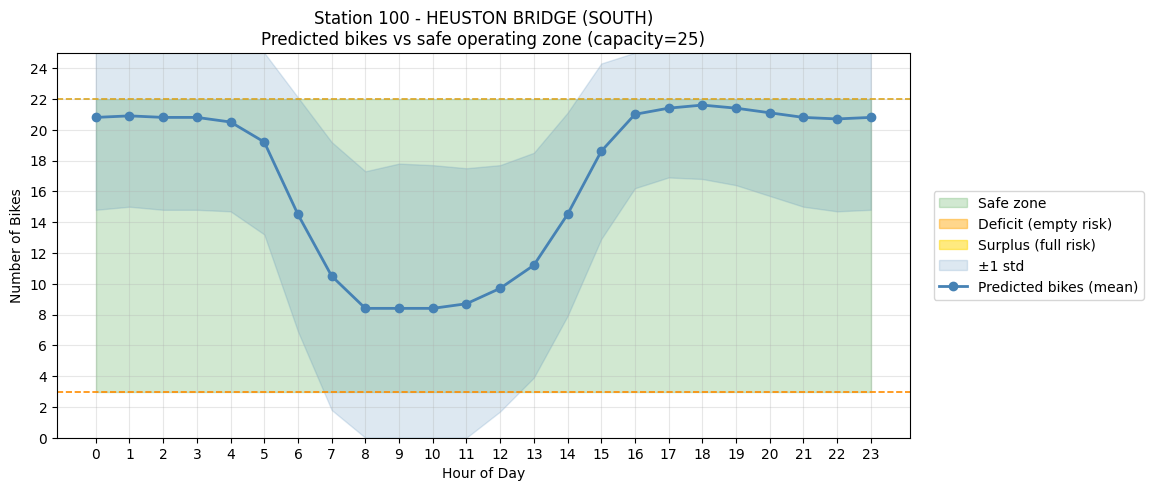

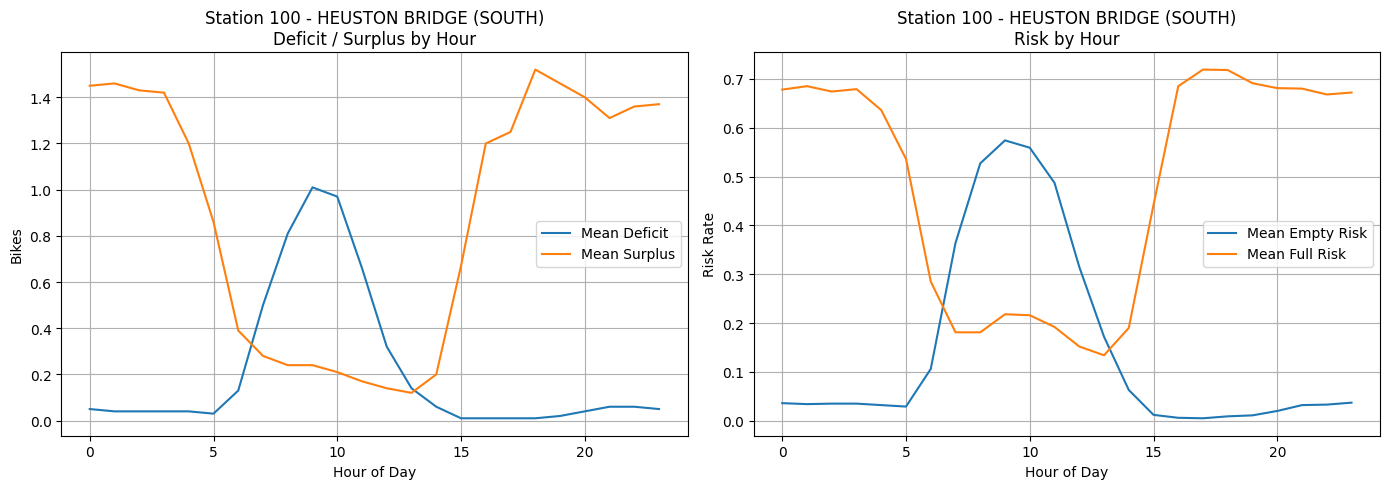

In [52]:
# Run selected station plot for top risk station

STATION_ID_SELECTED = 100 # change 

plot_selected_station(
    df_threshold,
    station_hour_summary,
    station_id_selected=STATION_ID_SELECTED,
    min_bikes_buffer=MIN_BIKES_BUFFER,
    min_docks_buffer=MIN_DOCKS_BUFFER,
)

In [13]:

def run_threshold_analysis(df_input, min_bikes_buffer=3, min_docks_buffer=3, station_id_selected=None):
    import numpy as np
    import matplotlib.pyplot as plt
    from sklearn.metrics import classification_report

    df = df_input.copy()


    #  Station name handling
    # -----------------------------
    name_candidates = ["name", "station_name", "station_name_clean"]
    name_col = next((c for c in name_candidates if c in df.columns), None)


    # Clip predicted bikes to physical bounds
    df["pred_bikes_tplus_30_clipped"] = df["pred_bikes_tplus_30"].clip(lower=0, upper=df["capacity"])
    df["pred_free_docks_tplus_30_clipped"] = df["capacity"] - df["pred_bikes_tplus_30_clipped"]

    # True future risk labels
    df["empty_risk_true"] = df["true_bikes_tplus_30"] <= min_bikes_buffer
    df["full_risk_true"] = df["true_free_docks_tplus_30"] <= min_docks_buffer

    
    # Predicted future risk labels
    df["empty_risk_pred"] = df["pred_bikes_tplus_30_clipped"] <= min_bikes_buffer
    df["full_risk_pred"] = df["pred_free_docks_tplus_30_clipped"] <= min_docks_buffer


    # Bike deficit / surplus
    df["bike_deficit"] = (
        min_bikes_buffer - df["pred_bikes_tplus_30_clipped"]
    ).clip(lower=0)

    df["bike_surplus"] = (
        df["pred_bikes_tplus_30_clipped"] - (df["capacity"] - min_docks_buffer)
    ).clip(lower=0)

    # Optional rounded integer versions for tabular display
    df["bike_deficit_int"] = df["bike_deficit"].round().astype(int)
    df["bike_surplus_int"] = df["bike_surplus"].round().astype(int)


    # Simple business risk label
    df["risk"] = "normal"
    df.loc[df["empty_risk_pred"], "risk"] = "empty"
    df.loc[df["full_risk_pred"], "risk"] = "full"

    print(f"=== BIKE-BASED EMPTY RISK ({min_bikes_buffer}/{min_docks_buffer}) ===")
    print(classification_report(df["empty_risk_true"], df["empty_risk_pred"], zero_division=0))

    print(f"=== BIKE-BASED FULL RISK ({min_bikes_buffer}/{min_docks_buffer}) ===")
    print(classification_report(df["full_risk_true"], df["full_risk_pred"], zero_division=0))

   
    # Station-hour summary
    group_cols = ["station_id", "hour"]
    if name_col is not None:
        group_cols.insert(1, name_col)

    station_hour_summary = (
        df.groupby(group_cols, as_index=False)
        .agg(
            predicted_bikes_mean=("pred_bikes_tplus_30_clipped", "mean"),
            predicted_bikes_std=("pred_bikes_tplus_30_clipped", "std"),
            deficit_mean=("bike_deficit", "mean"),
            surplus_mean=("bike_surplus", "mean"),
            deficit_sum=("bike_deficit", "sum"),
            surplus_sum=("bike_surplus", "sum"),
            n_empty_risk=("empty_risk_pred", "sum"),
            n_full_risk=("full_risk_pred", "sum"),
            p_empty_risk=("empty_risk_pred", "mean"),
            p_full_risk=("full_risk_pred", "mean"),
            n_obs=("station_id", "size"),
            capacity=("capacity", "first"),
        )
    )

    station_hour_summary["predicted_bikes_mean"] = station_hour_summary["predicted_bikes_mean"].round(1)
    station_hour_summary["predicted_bikes_std"] = station_hour_summary["predicted_bikes_std"].fillna(0).round(1)
    station_hour_summary["deficit_mean"] = station_hour_summary["deficit_mean"].round(2)
    station_hour_summary["surplus_mean"] = station_hour_summary["surplus_mean"].round(2)
    station_hour_summary["deficit_sum"] = station_hour_summary["deficit_sum"].round(2)
    station_hour_summary["surplus_sum"] = station_hour_summary["surplus_sum"].round(2)
    station_hour_summary["p_empty_risk"] = station_hour_summary["p_empty_risk"].round(3)
    station_hour_summary["p_full_risk"] = station_hour_summary["p_full_risk"].round(3)

    station_hour_summary["risk"] = "normal"
    station_hour_summary.loc[station_hour_summary["n_empty_risk"] > 0, "risk"] = "empty"
    station_hour_summary.loc[station_hour_summary["n_full_risk"] > 0, "risk"] = "full"

    summary_cols = [
        "station_id", "hour", "predicted_bikes_mean", "predicted_bikes_std",
        "deficit_mean", "surplus_mean", "n_empty_risk", "n_full_risk", "risk"
    ]
    if name_col is not None:
        summary_cols.insert(1, name_col)

    display(station_hour_summary[summary_cols].head(20))

    top_station_risk_summary = station_hour_summary.sort_values(
        ["deficit_mean", "surplus_mean", "predicted_bikes_mean"],
        ascending=[False, False, True]
    )[summary_cols].head(10)

    print("Top station-hour risk summary")
    display(top_station_risk_summary)

 
    # Global hourly aggregations
    agg_hour = (
        station_hour_summary
        .groupby("hour", as_index=False)
        .agg(
            total_deficit=("deficit_mean", "sum"),
            total_surplus=("surplus_mean", "sum"),
            mean_deficit=("deficit_mean", "mean"),
            mean_surplus=("surplus_mean", "mean"),
            total_predicted_bikes=("predicted_bikes_mean", "sum"),
            mean_predicted_bikes=("predicted_bikes_mean", "mean"),
        )
    )

    agg_hour_risk = (
        station_hour_summary
        .groupby("hour", as_index=False)
        .agg(
            total_empty_risk=("n_empty_risk", "sum"),
            total_full_risk=("n_full_risk", "sum"),
            mean_empty_risk=("p_empty_risk", "mean"),
            mean_full_risk=("p_full_risk", "mean"),
        )
    )


    # Plot 1: Deficit / Surplus by hour (sum vs mean)

    fig, axes = plt.subplots(1, 2, figsize=(14, 5), sharex=True)

    axes[0].plot(agg_hour["hour"], agg_hour["total_deficit"], label="Total Deficit")
    axes[0].plot(agg_hour["hour"], agg_hour["total_surplus"], label="Total Surplus")
    axes[0].set_xlabel("Hour of Day")
    axes[0].set_ylabel("Number of Bikes")
    axes[0].set_title(f"Deficit / Surplus by Hour - Total ({min_bikes_buffer}/{min_docks_buffer})")
    axes[0].legend()
    axes[0].grid(True)

    axes[1].plot(agg_hour["hour"], agg_hour["mean_deficit"], label="Mean Deficit")
    axes[1].plot(agg_hour["hour"], agg_hour["mean_surplus"], label="Mean Surplus")
    axes[1].set_xlabel("Hour of Day")
    axes[1].set_ylabel("Bikes per Station")
    axes[1].set_title(f"Deficit / Surplus by Hour - Mean ({min_bikes_buffer}/{min_docks_buffer})")
    axes[1].legend()
    axes[1].grid(True)

    plt.tight_layout()
    plt.show()

  
    # Plot 2: Risk by hour (sum vs mean)

    fig, axes = plt.subplots(1, 2, figsize=(14, 5), sharex=True)

    axes[0].plot(agg_hour_risk["hour"], agg_hour_risk["total_empty_risk"], label="Total Empty Risk")
    axes[0].plot(agg_hour_risk["hour"], agg_hour_risk["total_full_risk"], label="Total Full Risk")
    axes[0].set_xlabel("Hour of Day")
    axes[0].set_ylabel("Count of Risk Events")
    axes[0].set_title(f"Risk by Hour - Total ({min_bikes_buffer}/{min_docks_buffer})")
    axes[0].legend()
    axes[0].grid(True)

    axes[1].plot(agg_hour_risk["hour"], agg_hour_risk["mean_empty_risk"], label="Mean Empty Risk")
    axes[1].plot(agg_hour_risk["hour"], agg_hour_risk["mean_full_risk"], label="Mean Full Risk")
    axes[1].set_xlabel("Hour of Day")
    axes[1].set_ylabel("Average Risk Rate")
    axes[1].set_title(f"Risk by Hour - Mean ({min_bikes_buffer}/{min_docks_buffer})")
    axes[1].legend()
    axes[1].grid(True)

    plt.tight_layout()
    plt.show()


    # Plot 3: Predicted bikes by hour (sum vs mean)

    fig, axes = plt.subplots(1, 2, figsize=(14, 5), sharex=True)

    axes[0].plot(agg_hour["hour"], agg_hour["total_predicted_bikes"], label="Total Predicted Bikes")
    axes[0].set_xlabel("Hour of Day")
    axes[0].set_ylabel("Total Bikes")
    axes[0].set_title(f"Predicted Bikes by Hour - Total ({min_bikes_buffer}/{min_docks_buffer})")
    axes[0].legend()
    axes[0].grid(True)

    axes[1].plot(agg_hour["hour"], agg_hour["mean_predicted_bikes"], label="Mean Predicted Bikes")
    axes[1].set_xlabel("Hour of Day")
    axes[1].set_ylabel("Average Bikes per Station")
    axes[1].set_title(f"Predicted Bikes by Hour - Mean ({min_bikes_buffer}/{min_docks_buffer})")
    axes[1].legend()
    axes[1].grid(True)

    plt.tight_layout()
    plt.show()


    # Station-level plots

    if station_id_selected is not None:
        df_station = station_hour_summary[
            station_hour_summary["station_id"] == station_id_selected
        ].copy().sort_values("hour")

        if not df_station.empty:
            # Station name lookup
            if name_col is not None and name_col in df_station.columns:
                station_name = df_station[name_col].dropna().iloc[0]
            else:
                name_values = df.loc[df["station_id"] == station_id_selected, name_col].dropna().unique() if name_col else []
                station_name = name_values[0] if len(name_values) > 0 else f"Station {station_id_selected}"

            capacity_values = df.loc[df["station_id"] == station_id_selected, "capacity"].dropna().unique()
            capacity = float(capacity_values[0]) if len(capacity_values) > 0 else float(df_station["capacity"].iloc[0])
            upper_safe_limit = capacity - min_docks_buffer

            x = df_station["hour"].to_numpy()
            y = df_station["predicted_bikes_mean"].to_numpy()
            y_std = df_station["predicted_bikes_std"].fillna(0).to_numpy()

            lower_band = np.clip(y - y_std, 0, capacity)
            upper_band = np.clip(y + y_std, 0, capacity)

            # Station bike plot with safe zone and variance band
            plt.figure(figsize=(11, 5))

            # Safe zone
            plt.fill_between(
                x,
                min_bikes_buffer,
                upper_safe_limit,
                color="green",
                alpha=0.18,
                label="Safe zone"
            )

            # Deficit zone
            plt.fill_between(
                x,
                y,
                min_bikes_buffer,
                where=(y < min_bikes_buffer),
                interpolate=True,
                color="orange",
                alpha=0.45,
                label="Deficit (empty risk)"
            )

            # Surplus zone
            plt.fill_between(
                x,
                upper_safe_limit,
                y,
                where=(y > upper_safe_limit),
                interpolate=True,
                color="gold",
                alpha=0.50,
                label="Surplus (full risk)"
            )

            # Variance band
            plt.fill_between(
                x,
                lower_band,
                upper_band,
                color="gray",
                alpha=0.18,
                label="±1 std"
            )

            # Predicted bikes line
            plt.plot(
                x, y,
                marker="o",
                linewidth=2,
                color="steelblue",
                label="Predicted bikes (mean)"
            )

            # Threshold lines
            plt.axhline(min_bikes_buffer, linestyle="--", linewidth=1.2, color="darkorange")
            plt.axhline(upper_safe_limit, linestyle="--", linewidth=1.2, color="goldenrod")

            plt.ylim(0, capacity)
            plt.xticks(range(24))
            plt.xlabel("Hour of Day")
            plt.ylabel("Number of Bikes")
            plt.title(
                f"Station {station_id_selected} - {station_name}\n"
                f"Predicted bikes vs safe operating zone (capacity={int(capacity)})"
            )
            plt.grid(True, alpha=0.3)
            plt.legend()
            plt.show()

            # Station-level side-by-side summary
            fig, axes = plt.subplots(1, 2, figsize=(14, 5), sharex=True)

            axes[0].plot(df_station["hour"], df_station["deficit_mean"], label="Mean Deficit")
            axes[0].plot(df_station["hour"], df_station["surplus_mean"], label="Mean Surplus")
            axes[0].set_xlabel("Hour of Day")
            axes[0].set_ylabel("Bikes")
            axes[0].set_title(f"Station {station_id_selected} - {station_name}\nDeficit / Surplus by Hour")
            axes[0].legend()
            axes[0].grid(True)

            axes[1].plot(df_station["hour"], df_station["p_empty_risk"], label="Mean Empty Risk")
            axes[1].plot(df_station["hour"], df_station["p_full_risk"], label="Mean Full Risk")
            axes[1].set_xlabel("Hour of Day")
            axes[1].set_ylabel("Risk Rate")
            axes[1].set_title(f"Station {station_id_selected} - {station_name}\nRisk by Hour")
            axes[1].legend()
            axes[1].grid(True)

            plt.tight_layout()
            plt.show()

        else:
            print(f"No rows found for station_id={station_id_selected}")

    return df, station_hour_summary, agg_hour, agg_hour_risk, top_station_risk_summary

=== BIKE-BASED EMPTY RISK (3/3) ===
              precision    recall  f1-score   support

       False       0.96      0.97      0.97   4984104
        True       0.92      0.90      0.91   1798523

    accuracy                           0.95   6782627
   macro avg       0.94      0.93      0.94   6782627
weighted avg       0.95      0.95      0.95   6782627

=== BIKE-BASED FULL RISK (3/3) ===
              precision    recall  f1-score   support

       False       0.98      0.99      0.98   6139805
        True       0.88      0.81      0.84    642822

    accuracy                           0.97   6782627
   macro avg       0.93      0.90      0.91   6782627
weighted avg       0.97      0.97      0.97   6782627



,station_id,name,hour,predicted_bikes_mean,predicted_bikes_std,deficit_mean,surplus_mean,n_empty_risk,n_full_risk,risk
0,1,CLARENDON ROW,0,8.9,8.8,1.02,0.01,888,20,full
1,1,CLARENDON ROW,1,8.6,8.7,1.06,0.00,861,19,full
2,1,CLARENDON ROW,2,8.6,8.7,1.07,0.01,901,20,full
3,1,CLARENDON ROW,3,8.7,8.8,1.05,0.01,897,24,full
4,1,CLARENDON ROW,4,9.0,8.4,0.76,0.00,925,22,full
5,1,CLARENDON ROW,5,10.9,8.1,0.23,0.02,637,58,full
6,1,CLARENDON ROW,6,13.6,7.6,0.02,0.07,145,168,full
7,1,CLARENDON ROW,7,16.3,7.1,0.01,0.11,25,238,full
8,1,CLARENDON ROW,8,18.3,6.8,0.00,0.08,26,313,full
9,1,CLARENDON ROW,9,20.3,6.4,0.00,0.10,15,352,full


Top station-hour risk summary


,station_id,name,hour,predicted_bikes_mean,predicted_bikes_std,deficit_mean,surplus_mean,n_empty_risk,n_full_risk,risk
1179,51,YORK STREET WEST,3,1.0,4.4,2.78,0.0,1892,0,empty
1176,51,YORK STREET WEST,0,1.0,4.6,2.77,0.0,1942,0,empty
1177,51,YORK STREET WEST,1,1.0,4.6,2.77,0.0,1886,0,empty
1178,51,YORK STREET WEST,2,1.0,4.5,2.77,0.0,1897,0,empty
1180,51,YORK STREET WEST,4,1.1,4.5,2.76,0.0,1995,0,empty
1199,51,YORK STREET WEST,23,1.1,4.8,2.76,0.0,1998,0,empty
1198,51,YORK STREET WEST,22,1.1,4.7,2.75,0.0,1878,0,empty
1197,51,YORK STREET WEST,21,1.2,4.8,2.73,0.0,1887,6,full
1196,51,YORK STREET WEST,20,1.2,4.9,2.70,0.0,1881,7,full
1194,51,YORK STREET WEST,18,1.4,4.8,2.57,0.0,1870,0,empty


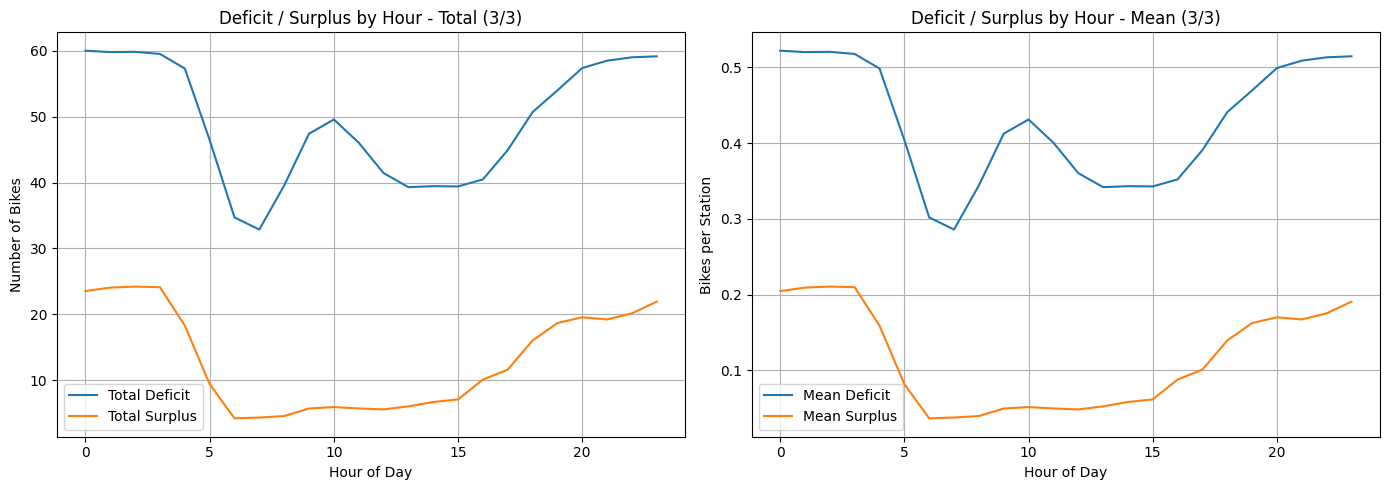

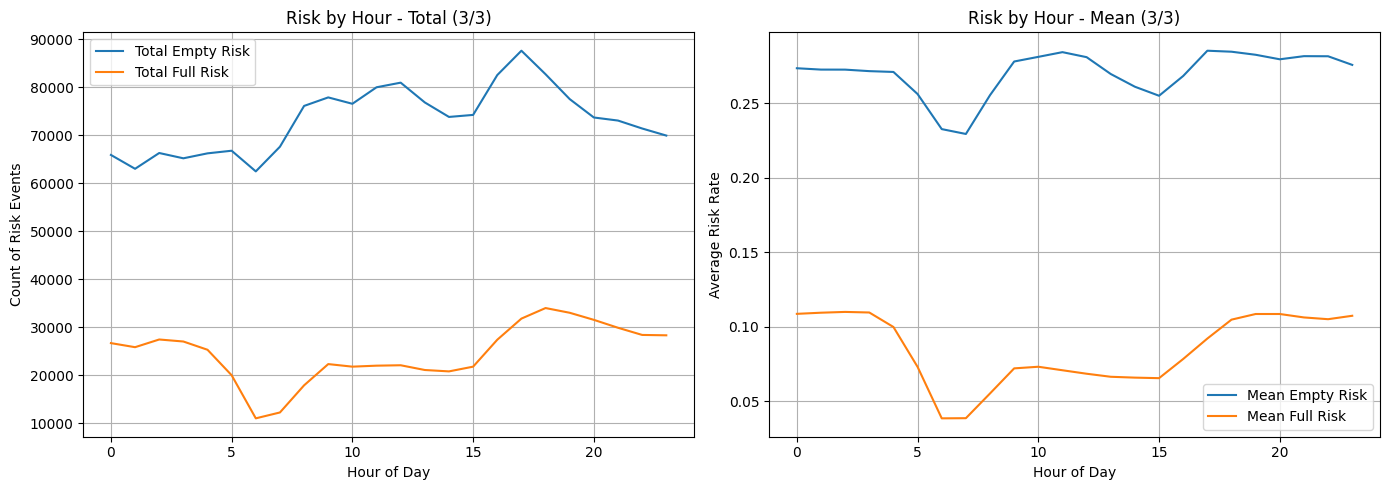

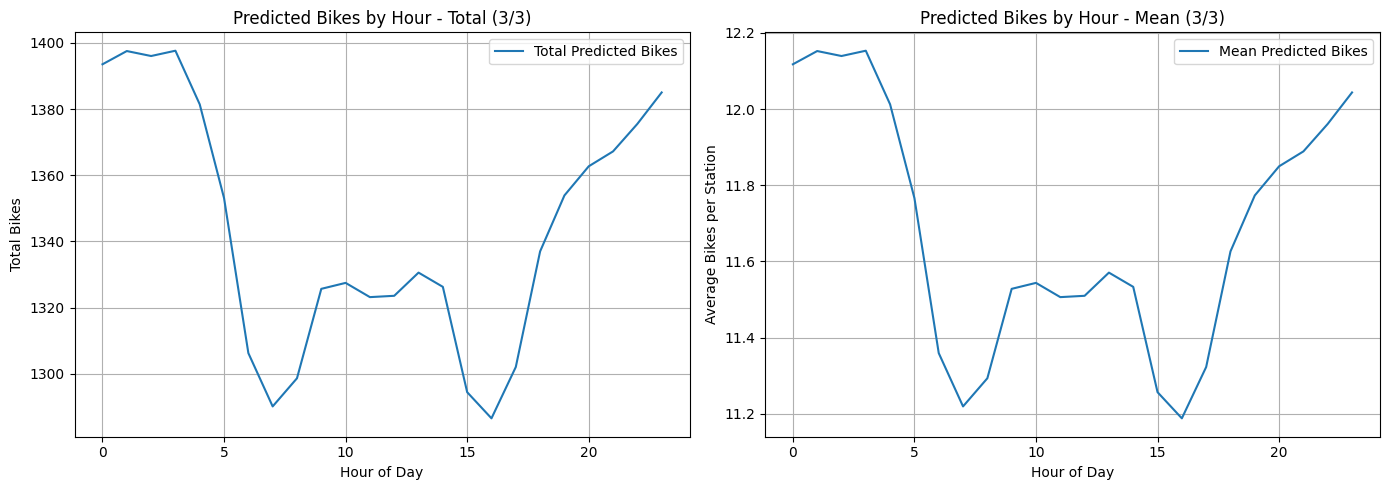

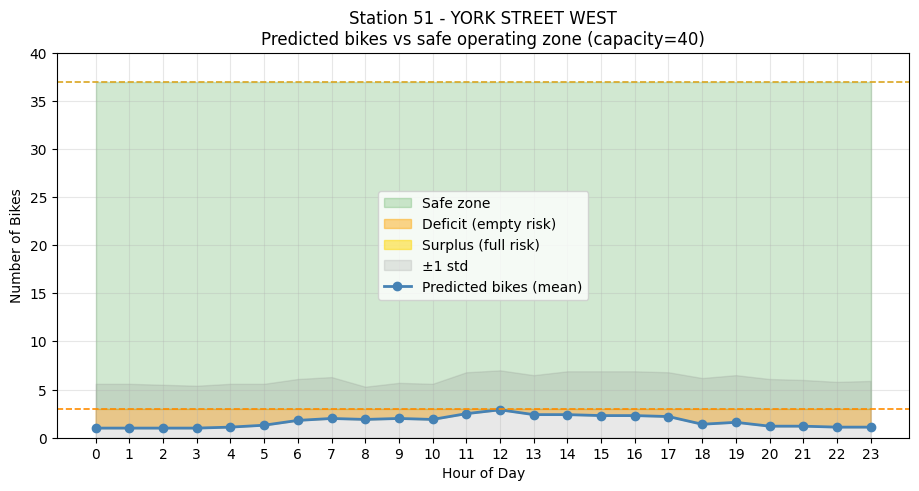

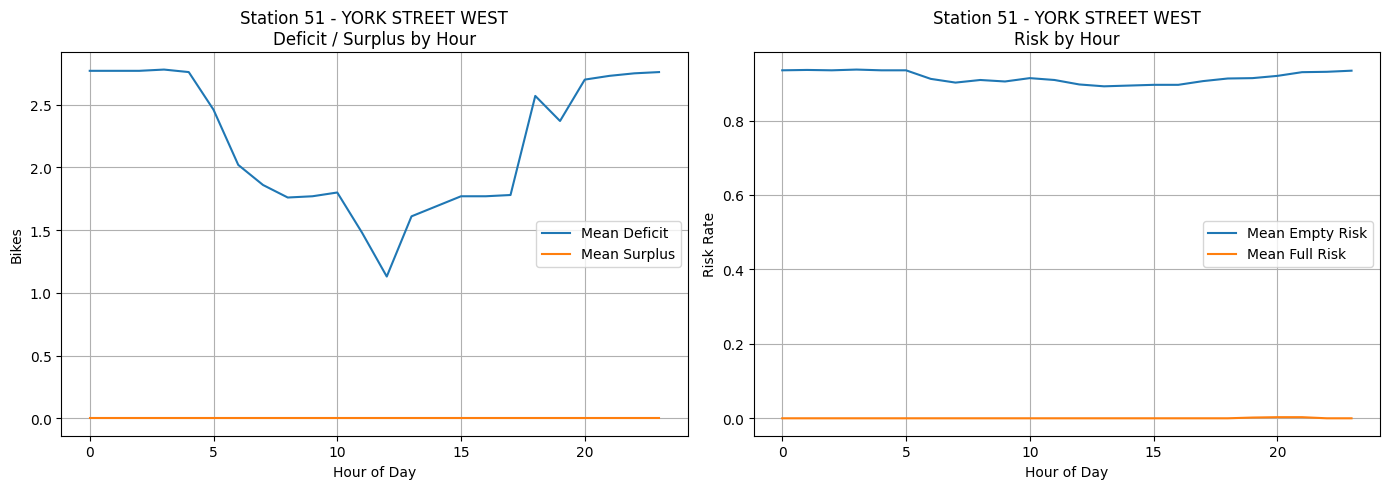

In [14]:

MIN_BIKES_BUFFER = 3
MIN_DOCKS_BUFFER = 3
STATION_ID_SELECTED = 51  # change for different station

df_threshold, station_hour_summary, agg_hour, agg_hour_risk, top_station_risk_summary = run_threshold_analysis(
    df_test,
    min_bikes_buffer=MIN_BIKES_BUFFER,
    min_docks_buffer=MIN_DOCKS_BUFFER,
    station_id_selected=STATION_ID_SELECTED,
)
